In [4]:
import pandas as pd

TOWNS = ["Babylon", "Brookhaven", "Huntington", "Islip", "Smithtown"]

tickets = pd.read_csv("ticket_data_clean.zip", usecols=["LOCATION", "MUNICIP", "CRIME_DATE"], dtype=str)

tickets["town"] = tickets["MUNICIP"].str.replace("TOWN OF ", "").str.title()

# Villages sit inside the five towns, so count their tickets under the town they belong to
VILLAGES = {
    "Village Of Islandia": "Islip",
    "Village Of Brightwaters": "Islip",
    "Village Of Patchogue": "Brookhaven",
    "Village Of Lake Grove": "Brookhaven",
    "Village Of Bellport": "Brookhaven",
    "Village Of Mastic Beach": "Brookhaven",
    "Village Of Babylon": "Babylon",
    "Village Of Lindenhurst": "Babylon",
    "Village Of Amityville": "Babylon",
    "Village Of Huntington Bay": "Huntington",
    "Village Of Northport": "Huntington",
}
tickets["town"] = tickets["town"].replace(VILLAGES)

tickets = tickets[tickets["town"].isin(TOWNS)]

print(len(tickets))
print(tickets["town"].value_counts())

494248
town
Brookhaven    184468
Islip         154360
Huntington     69062
Babylon        60649
Smithtown      25709
Name: count, dtype: int64


In [5]:
import re

# 1. Spelling swaps so every version of a word matches (left = what to find, right = what to use)
ABBREVIATIONS = [
    (r"\bAVENUE\b|\bAV\b", "AVE"),
    (r"\bROAD\b", "RD"),
    (r"\bSTREET\b", "ST"),
    (r"\bHIGHWAY\b|\bHGWY\b|\bHWAY\b|\bHW\b", "HWY"),
    (r"\bTURNPIKE\b|\bTPK\b|\bTNPK\b", "TPKE"),
    (r"\bPARKWAY\b|\bPKY\b|\bPWKY\b|\bPWY\b|\bPKWAY\b", "PKWY"),
    (r"\bBOULEVARD\b|\bBL\b", "BLVD"),
    (r"\bDRIVE\b", "DR"),
    (r"\bLANE\b", "LN"),
    (r"\bPLACE\b", "PL"),
    (r"\bCOURT\b", "CT"),
    (r"\bEXPRESSWAY\b|\bEXPWY\b|\bE ?WAY\b", "EXPY"),
    (r"\bCAUSEWAY\b", "CSWY"),
    (r"\bBYPASS\b", "BYP"),
    (r"\bSTATE PKWY\b", "PKWY"),
    (r"\bNORTH\b", "N"),
    (r"\bSOUTH\b", "S"),
    (r"\bEAST\b", "E"),
    (r"\bWEST\b", "W"),
    (r"\bMOUNT\b", "MT"),
    (r"\bCPT\b|\bCAPT\b", "CAPTAIN"),
    (r"\bVETS HWY\b", "VETERANS HWY"),
    (r"\bNY AVE\b", "NEW YORK AVE"),
    (r"\bBROAD ?HOLLOW RD\b", "RT 110"),
    (r"\bDPA\b", "DEER PARK AVE"),
    (r"\bLI AVE\b", "LONG ISLAND AVE"),
    (r"\bBAYSHORE RD\b", "BAY SHORE RD"),
    (r"\bSPUR (N|S)\b", r"SPUR DR \1"),
]

# 2. Route numbers that are really a named road
ROUTE_ALIASES = {
    "RT 27": "SUNRISE HWY",
    "RT 454": "VETERANS MEMORIAL HWY",
    "RT 347": "NESCONSET HWY",
    "RT 46": "WILLIAM FLOYD PKWY",
    "CR 46": "WILLIAM FLOYD PKWY",
    "CR 97": "NICOLLS RD",
    "RT 97": "NICOLLS RD",
    "RT 83": "CR 83",
}

RTE = r"(?:RT|RTE|ROUTE|NY|SR|STATE RTE)"

def basic_clean(text):
    s = str(text or "").upper()
    s = re.sub(r"\bC/R\b", "CR", s)
    s = re.sub(r"\bI/(\d)", r"I \1", s)
    s = re.sub(r"[.,'-]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    for pattern, replacement in ABBREVIATIONS:
        s = re.sub(pattern, replacement, s)
    return s

# 3. Recognize the major roads no matter how they were typed
def major_road(s):
    if re.search(r"\bEXPY\b|\bLIE\b|(^|[^0-9])495([^0-9]|$)", s): return "LONG ISLAND EXPY"
    if re.search(r"SOUTHERN ST|SOUTHERN PKWY|SSPK|\bSSP\b|\bSS PKWY\b", s): return "SOUTHERN STATE PKWY"
    if re.search(r"NORTHERN ST|NORTHERN PKWY|NSPK|\bNSP\b", s): return "NORTHERN STATE PKWY"
    if "SAGTIKOS" in s: return "SAGTIKOS PKWY"
    if "SUNKEN MEADOW" in s: return "SUNKEN MEADOW PKWY"
    if "ROBERT MOSES" in s and "PARK" not in s.replace("PKWY", ""): return "ROBERT MOSES CSWY"
    if re.search(r"SUNRISE(?! (AVE|DR|CT|LN|PL|ST|RD|BLVD|TER|PATH|TRL)\b)", s) or s == "27": return "SUNRISE HWY"
    if re.search(rf"VETERANS (MEM|HWY)|VETS MEM|\b{RTE} ?454\b|(^|\s)454(\s|$)", s): return "VETERANS MEMORIAL HWY"
    if re.search(rf"\b{RTE} ?112\b|(^|\s)112(\s|$)|PORT JEFFERSON AND PATCHOGUE", s): return "RT 112"
    if "WILLIAM FLOYD" in s or "WM FLOYD" in s: return "WILLIAM FLOYD PKWY"
    if "NICOLLS" in s: return "NICOLLS RD"
    if "MOTOR P" in s: return "MOTOR PKWY"
    if re.search(r"MONTAUK( HWY)?$|MONTAUK HWY", s): return "MONTAUK HWY"
    if "MIDDLE COUNTRY" in s: return "MIDDLE COUNTRY RD"
    if re.search(r"JERICHO( TPKE)?$|JERICHO TPKE", s): return "JERICHO TPKE"
    if ("NESCONSET" in s and "HWY" in s) or re.search(rf"\b{RTE} ?347\b", s): return "NESCONSET HWY"
    if re.fullmatch(r"\d{2,3}A?", s): return "RT " + s
    m = re.search(rf"\b{RTE} ?(\d{{2,3}}A?)\b", s)
    if m: return "RT " + m.group(1)
    m = re.search(r"\b(?:CR|CO RD|COUNTY RD) ?(\d{1,3}A?)\b", s)
    if m: return "CR " + m.group(1)
    return None

def use_alias(name):
    return ROUTE_ALIASES.get(name, name) if name else name

# 4. Junk at the start of a location, and words that start a cross street
LEADING_JUNK = r"^(?:(?:N|S|E|W)/?B\s+|(?:NB|SB|EB|WB)\s+|C/O\s+|I/F/O\s+|I/O\s+|IFO\s+|P/L(?:OT)?(?:\s+OF)?\s+|IN FRONT OF\s+|CORNER OF\s+)+"
CROSS_STREET = r"\s*(?:@|&| AND | AT | X | / |/| E/O | W/O | N/O | S/O | NEAR | EXIT | OPP | IFO )\s*"

# 5. Clean one ticket location into a road name
def ticket_road(location):
    s = basic_clean(location)
    s = re.sub(LEADING_JUNK, "", s)
    found = major_road(s)
    if found: return use_alias(found)
    s = re.split(CROSS_STREET, s)[0]
    s = re.sub(r"^\d+\s+", "", s)
    s = re.sub(r"\s+(N|S|E|W)/?B$", "", s).strip()
    found = major_road(s)
    if found: return use_alias(found)
    return s or None

# 6. Same rules for the Census road names
def census_road(name):
    s = basic_clean(name)
    return use_alias(major_road(s)) or s

# Test on a few real examples
for example in ["W/B 495 X 53", "EB 27 X 62", "EB SR454 AT JULIA GOLDBACH", "2975 HORSEBLOCK RD", "C/O 5TH AVE&ATLANTIC ST"]:
    print(f"{example:32} ->  {ticket_road(example)}")

W/B 495 X 53                     ->  LONG ISLAND EXPY
EB 27 X 62                       ->  SUNRISE HWY
EB SR454 AT JULIA GOLDBACH       ->  VETERANS MEMORIAL HWY
2975 HORSEBLOCK RD               ->  HORSEBLOCK RD
C/O 5TH AVE&ATLANTIC ST          ->  5TH AVE


In [6]:
unique_locations = tickets["LOCATION"].dropna().unique()
lookup = {loc: ticket_road(loc) for loc in unique_locations}
tickets["road_key"] = tickets["LOCATION"].map(lookup)

print(len(unique_locations))
print(tickets["road_key"].value_counts().head(15))

77428
road_key
LONG ISLAND EXPY         98653
SUNRISE HWY              41797
SOUTHERN STATE PKWY      20073
MIDDLE COUNTRY RD        11955
RT 112                   10020
WILLIAM FLOYD PKWY        9747
MONTAUK HWY               9632
JERICHO TPKE              9327
VETERANS MEMORIAL HWY     8792
SUFFOLK AVE               6617
NEW YORK AVE              5560
NESCONSET HWY             5394
RT 110                    5286
STRAIGHT PATH             5107
CR 83                     4387
Name: count, dtype: int64


In [7]:
import geopandas as gpd

# Town borders: keep only the five towns in Suffolk County (county code 103)
towns = gpd.read_file("tl_2024_36_cousub.zip")
towns = towns[(towns["COUNTYFP"] == "103") & (towns["NAME"].isin(TOWNS))][["NAME", "geometry"]]
towns = towns.rename(columns={"NAME": "town"}).to_crs(2263)

# Roads: clean the Census road names with the same rules as the tickets
roads = gpd.read_file("tl_2024_36103_roads.zip").to_crs(2263)
roads["road_key"] = roads["FULLNAME"].fillna("").map(census_road)

# Cut every road where it crosses a town line, and tag each piece with its town
road_pieces = gpd.overlay(roads[["FULLNAME", "road_key", "geometry"]], towns, how="intersection", keep_geom_type=True)

print(len(roads), "roads in Suffolk County")
print(len(road_pieces), "road pieces inside the five towns")

38971 roads in Suffolk County
28281 road pieces inside the five towns


In [8]:
# Every cleaned road name that exists in each town
names_in_town = {t: set(road_pieces.loc[road_pieces["town"] == t, "road_key"]) for t in TOWNS}

def match(town, key):
    """Find the road in the same town. Exact name first, then the closest name."""
    if not isinstance(key, str) or not key:
        return None
    names = names_in_town[town]
    if key in names:
        return key
    # Ticket has extra words: "CROOKED HILL RD DOT SITE" -> "CROOKED HILL RD"
    starts = [n for n in names if n and len(n) >= 6 and key.startswith(n + " ")]
    if starts:
        return max(starts, key=len)
    # Ticket is missing the ending: "PULASKI" -> "PULASKI RD"
    longer = [n for n in names if len(key) >= 4 and n.startswith(key + " ")]
    if longer:
        return min(longer, key=len)
    return None

# Match each town + road combination once, then copy the answer to every ticket
pairs = tickets[["town", "road_key"]].drop_duplicates()
pairs["matched"] = [match(t, k) for t, k in zip(pairs["town"], pairs["road_key"])]
tickets = tickets.drop(columns="matched", errors="ignore").merge(pairs, on=["town", "road_key"], how="left")

print(f"Matched {tickets['matched'].notna().mean():.1%} of tickets to a road")

# Count tickets per road, per town
counts = tickets.dropna(subset=["matched"]).groupby(["town", "matched"]).size().rename("tickets").reset_index()
print(counts.sort_values("tickets", ascending=False).head(15))

Matched 95.6% of tickets to a road
            town                matched  tickets
1507  Brookhaven       LONG ISLAND EXPY    44224
3330       Islip       LONG ISLAND EXPY    30470
3673       Islip            SUNRISE HWY    21960
2533  Huntington       LONG ISLAND EXPY    21872
2018  Brookhaven            SUNRISE HWY    15577
3642       Islip    SOUTHERN STATE PKWY    12385
1590  Brookhaven      MIDDLE COUNTRY RD    11390
1894  Brookhaven                 RT 112     9984
2159  Brookhaven     WILLIAM FLOYD PKWY     9747
659      Babylon    SOUTHERN STATE PKWY     7663
2491  Huntington           JERICHO TPKE     7635
1615  Brookhaven            MONTAUK HWY     7065
3668       Islip            SUFFOLK AVE     6733
3722       Islip  VETERANS MEMORIAL HWY     6216
2587  Huntington           NEW YORK AVE     5575


In [9]:
# Pick the time period: None = all tickets (2024 to Oct 2026), or "2025" for just 2025
YEAR = None

source = tickets if YEAR is None else tickets[tickets["CRIME_DATE"].str[:4] == YEAR]
counts = source.dropna(subset=["matched"]).groupby(["town", "matched"]).size().rename("tickets").reset_index()

# Attach each road's ticket count to its map lines (roads with no tickets are dropped)
mapped = road_pieces.merge(counts, left_on=["town", "road_key"], right_on=["town", "matched"], how="inner")
mapped = mapped.dissolve(by=["town", "road_key"], aggfunc={"tickets": "first", "FULLNAME": "first"}).reset_index()
mapped = mapped.sort_values("tickets")

# Town borders run out into the water, so trace the land from where the roads are
road_area = roads.geometry.buffer(700)
road_area = road_area.union_all() if hasattr(road_area, "union_all") else road_area.unary_union
land = road_area.buffer(-350)
towns_land = towns.copy()
towns_land["geometry"] = towns.geometry.intersection(land)

print(len(mapped), "roads with tickets")

4079 roads with tickets


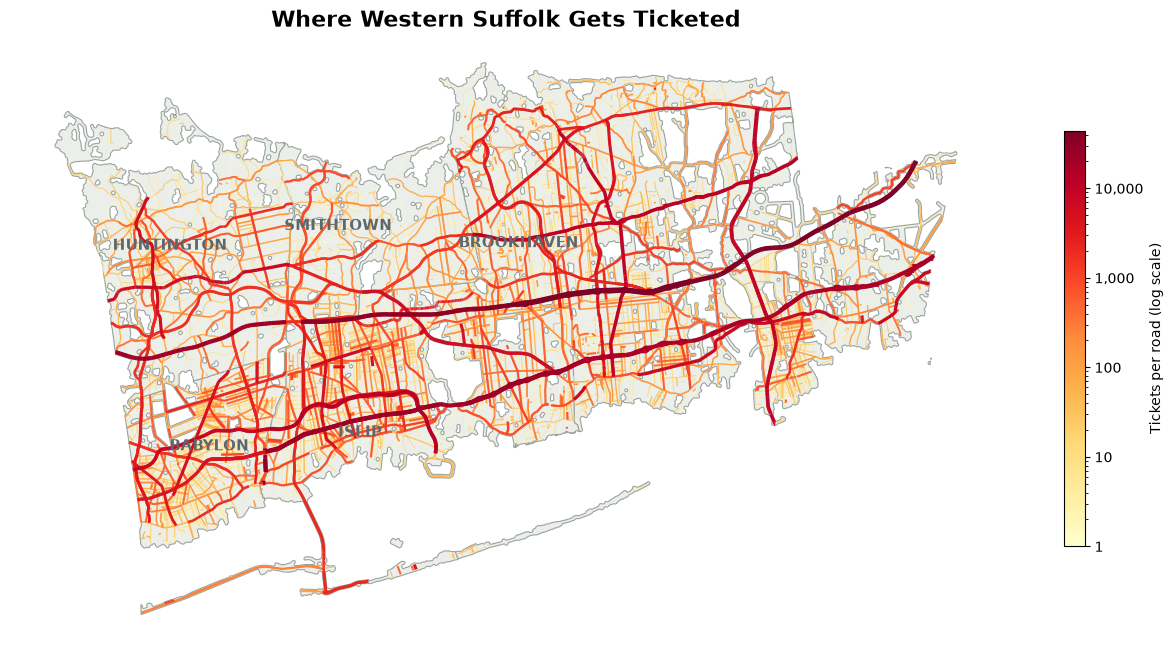

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Color scale: yellow (few tickets) to dark red (most), on a log scale
norm = mcolors.LogNorm(vmin=1, vmax=mapped["tickets"].max())
cmap = plt.get_cmap("YlOrRd")

# Busier roads are drawn thicker
widths = 0.3 + 2.7 * (np.log10(mapped["tickets"]) / np.log10(mapped["tickets"].max())) ** 1.5

fig, ax = plt.subplots(figsize=(16, 9))

# Land and town lines first, then roads on top
towns_land.plot(ax=ax, color="#eceee9", edgecolor="#9aa49f", linewidth=0.8)
mapped.plot(ax=ax, color=cmap(norm(mapped["tickets"])), linewidth=widths)

# Town names
for _, row in towns_land.iterrows():
    p = row.geometry.representative_point()
    ax.annotate(row["town"].upper(), (p.x, p.y), ha="center", fontsize=11, color="#5d686e", weight="bold")

# Legend bar with plain numbers
ticks = [v for v in [1, 10, 100, 1000, 10000] if v <= mapped["tickets"].max()]
bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label="Tickets per road (log scale)")
bar.set_ticks(ticks)
bar.set_ticklabels([f"{v:,}" for v in ticks])

title = "Where Western Suffolk Gets Ticketed"
ax.set_title(title if YEAR is None else f"{title} ({YEAR})", fontsize=16, weight="bold")
ax.set_axis_off()

plt.savefig("suffolk_ticket_roads.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
import folium

# Web maps use latitude/longitude, so switch back from the Long Island projection
web = mapped.to_crs(4326)
web["geometry"] = web.geometry.simplify(0.0001)   # lighter lines so the map loads fast

# Same colors and thicknesses as the static map
web["color"] = [mcolors.to_hex(cmap(norm(v))) for v in web["tickets"]]
web["width"] = (1 + 5 * (np.log10(web["tickets"]) / np.log10(web["tickets"].max())) ** 1.5).round(2)
web["road"] = web["road_key"].str.title()

# Base map centered on western Suffolk, with a light gray street map underneath
m = folium.Map(location=[40.82, -73.1], zoom_start=10, tiles="Esri.WorldGrayCanvas")
# Town borders
folium.GeoJson(
    towns.to_crs(4326),
    style_function=lambda f: {"color": "#7a8580", "weight": 1.5, "fillOpacity": 0},
    tooltip=folium.GeoJsonTooltip(fields=["town"], aliases=["Town"]),
).add_to(m)

# Roads, colored by ticket count, with hover info
folium.GeoJson(
    web[["road", "town", "tickets", "color", "width", "geometry"]],
    style_function=lambda f: {"color": f["properties"]["color"], "weight": f["properties"]["width"], "opacity": 0.9},
    highlight_function=lambda f: {"weight": 8},
    tooltip=folium.GeoJsonTooltip(fields=["road", "town", "tickets"], aliases=["Road", "Town", "Tickets"], localize=True),
).add_to(m)

m.save("suffolk_ticket_roads.html")

In [12]:
import json
import folium
from branca.element import Element

# ---------- Settings ----------
# 2020 Census population of each town (for tickets per 1,000 residents)
POPULATION = {"Babylon": 218177, "Brookhaven": 485631, "Huntington": 204179, "Islip": 339982, "Smithtown": 116337}

# Roads counted as highways for the "share on highways" stat
HIGHWAYS = {"LONG ISLAND EXPY", "SOUTHERN STATE PKWY", "NORTHERN STATE PKWY", "SUNRISE HWY",
            "SAGTIKOS PKWY", "SUNKEN MEADOW PKWY", "ROBERT MOSES CSWY", "HECKSCHER PKWY"}

# The periods in the switch: (short key, label shown on the map, year or None for all)
PERIODS = [("all", "All years (Jan 2024 to Oct 2026)", None),
           ("y2024", "2024 only", "2024"),
           ("y2025", "2025 only", "2025"),
           ("y2026", "2026 (through Oct 8)", "2026")]

tickets["year"] = tickets["CRIME_DATE"].str[:4]
tickets["date"] = pd.to_datetime(tickets["CRIME_DATE"], errors="coerce")

def period_tickets(year):
    return tickets if year is None else tickets[tickets["year"] == year]

# ---------- 1. Ticket counts per road, for every period ----------
per_road = {}
for key, label, year in PERIODS:
    part = period_tickets(year)
    per_road[key] = part.dropna(subset=["matched"]).groupby(["town", "matched"]).size()
per_road = pd.DataFrame(per_road).fillna(0).astype(int).reset_index().rename(columns={"matched": "road_key"})

roads_all = road_pieces.merge(per_road, on=["town", "road_key"], how="inner")
roads_all = roads_all.dissolve(by=["town", "road_key"], aggfunc={k: "first" for k, _, _ in PERIODS}).reset_index()
roads_all = roads_all.to_crs(4326)
roads_all["geometry"] = roads_all.geometry.simplify(0.0001)
roads_all["road"] = roads_all["road_key"].str.title()

# ---------- 2. Stats for every period ----------
stats = {}
for key, label, year in PERIODS:
    part = period_tickets(year)
    placed = part.dropna(subset=["matched"])
    ranked = roads_all[roads_all[key] > 0].sort_values(key, ascending=False)
    days = part["date"].dt.day_name().value_counts()
    # October 2026 is only 8 days long, so leave it out of the month comparison
    full_months = part[~((part["year"] == "2026") & (part["date"].dt.month == 10))]
    # Average per month, since some months show up in more years than others
    months = (full_months.groupby([full_months["year"], full_months["date"].dt.month_name()]).size()
              .groupby(level=1).mean().sort_values(ascending=False))

    town_rows = []
    for town in sorted(POPULATION, key=lambda t: -(part["town"] == t).sum()):
        n = int((part["town"] == town).sum())
        top_road = ranked[ranked["town"] == town].iloc[0]["road"] if (ranked["town"] == town).any() else ""
        town_rows.append({"town": town, "tickets": n, "per1000": round(n / POPULATION[town] * 1000), "top": top_road})

    top10 = []
    for r in ranked.head(10).itertuples():
        x0, y0, x1, y1 = r.geometry.bounds
        top10.append({"road": r.road, "town": r.town, "n": int(getattr(r, key)), "b": [[y0, x0], [y1, x1]]})

    stats[label] = {
        "tickets": len(part),
        "placed": len(placed),
        "placed_pct": round(len(placed) / len(part) * 100, 1),
        "roads": int((roads_all[key] > 0).sum()),
        "highway_pct": round(placed["matched"].isin(HIGHWAYS).mean() * 100),
        "top10_pct": round(ranked.head(10)[key].sum() / len(placed) * 100),
        "per_day": round(len(part) / part["date"].nunique()),
        "busiest_day": days.index[0],
        "busiest_day_pct": round(days.iloc[0] / len(part) * 100),
        "busiest_month": months.index[0],
        "quietest_month": months.index[-1],
        "towns": town_rows,
        "top10": top10,
    }

# ---------- 3. The map ----------
m = folium.Map(location=[40.82, -73.1], zoom_start=10, tiles=None)
folium.TileLayer("Esri.WorldGrayCanvas", control=False).add_to(m)
folium.GeoJson(towns.to_crs(4326), control=False,
               style_function=lambda f: {"color": "#7a8580", "weight": 1.5, "fillOpacity": 0}).add_to(m)

tooltip_fields = ["road", "town"] + [k for k, _, _ in PERIODS]
tooltip_names = ["Road", "Town"] + [f"Tickets, {label}" for _, label, _ in PERIODS]

for i, (key, label, year) in enumerate(PERIODS):
    layer = roads_all[roads_all[key] > 0].sort_values(key).copy()
    top = layer[key].max()
    scale = mcolors.LogNorm(vmin=1, vmax=top)
    layer["color"] = [mcolors.to_hex(cmap(scale(v))) for v in layer[key]]
    layer["width"] = (1 + 5 * (np.log10(layer[key]) / np.log10(top)) ** 1.5).round(2)
    group = folium.FeatureGroup(name=label, overlay=False, show=(i == 0))
    folium.GeoJson(
        layer[tooltip_fields + ["color", "width", "geometry"]],
        style_function=lambda f: {"color": f["properties"]["color"], "weight": f["properties"]["width"], "opacity": 0.9},
        highlight_function=lambda f: {"weight": 9},
        tooltip=folium.GeoJsonTooltip(fields=tooltip_fields, aliases=tooltip_names, localize=True),
    ).add_to(group)
    group.add_to(m)

folium.LayerControl(position="bottomright", collapsed=False).add_to(m)

# ---------- 4. The stats panel (updates when you switch years) ----------
ramp = ", ".join(mcolors.to_hex(cmap(x)) for x in np.linspace(0, 1, 7))
panel = """
<style>
  #panel {position:fixed; top:12px; right:12px; z-index:9999; width:320px; max-height:calc(100vh - 230px); overflow:auto;
          background:#fff; border:1px solid #ccc; border-radius:8px; padding:14px; font:13px Arial, sans-serif;
          box-shadow:0 2px 10px rgba(0,0,0,.15)}
  #panel h1 {font-size:17px; margin:0 0 2px; padding-right:50px}
  #panel h2 {font-size:12px; text-transform:uppercase; letter-spacing:.06em; color:#555; margin:14px 0 6px}
  #panel .sub {color:#666}
  #panel .grid {display:grid; grid-template-columns:1fr 1fr; gap:10px}
  #panel .big {font-size:19px; font-weight:bold}
  #panel .lbl {color:#666; font-size:12px}
  #panel table {width:100%; border-collapse:collapse}
  #panel td, #panel th {padding:4px 2px; text-align:left; vertical-align:top}
  #panel th {color:#666; font-weight:normal; font-size:12px; border-bottom:1px solid #ddd}
  #panel .num {text-align:right; font-variant-numeric:tabular-nums}
  #panel tr.zoom {cursor:pointer} #panel tr.zoom:hover {background:#f3f3f3}
  #panel .ramp {height:12px; border-radius:3px; background:linear-gradient(90deg, RAMP)}
  #panel .ticks {display:flex; justify-content:space-between; color:#666; font-size:11px; margin-top:3px}
  #hide {position:absolute; top:10px; right:10px; border:1px solid #ccc; background:#fff; border-radius:4px; cursor:pointer}
  #show {position:fixed; top:12px; right:12px; z-index:9999; display:none; padding:8px 12px; border:1px solid #ccc;
         background:#fff; border-radius:6px; cursor:pointer; font:13px Arial, sans-serif}
</style>
<button id="show" onclick="document.getElementById('panel').style.display='block'; this.style.display='none'">Show stats</button>
<div id="panel">
  <button id="hide" onclick="document.getElementById('panel').style.display='none'; document.getElementById('show').style.display='block'">Hide</button>
  <h1>Where Western Suffolk Gets Ticketed</h1>
  <div class="sub" id="period"></div>
  <div id="body"></div>
</div>
<script>
const STATS = STATS_JSON;
const fmt = n => n.toLocaleString();
function render(label) {
  const s = STATS[label];
  if (!s) return;
  document.getElementById("period").textContent = label + ". Switch years at the bottom right.";
  let towns = s.towns.map(t => `<tr><td>${t.town}</td><td class="num">${fmt(t.tickets)}</td><td class="num">${fmt(t.per1000)}</td><td>${t.top}</td></tr>`).join("");
  let top = s.top10.map((r, i) => `<tr class="zoom" onclick='MAP.fitBounds(${JSON.stringify(r.b)})'><td style="color:#888">${i + 1}</td><td><b>${r.road}</b><br><span class="lbl">${r.town}</span></td><td class="num">${fmt(r.n)}</td></tr>`).join("");
  document.getElementById("body").innerHTML = `
    <h2>At a glance</h2>
    <div class="grid">
      <div><div class="big">${fmt(s.tickets)}</div><div class="lbl">tickets written</div></div>
      <div><div class="big">${fmt(s.per_day)}</div><div class="lbl">tickets per day</div></div>
      <div><div class="big">${s.highway_pct}%</div><div class="lbl">on highways and parkways</div></div>
      <div><div class="big">${s.top10_pct}%</div><div class="lbl">on the 10 busiest roads</div></div>
      <div><div class="big">${s.busiest_day}</div><div class="lbl">busiest day (${s.busiest_day_pct}% of tickets)</div></div>
      <div><div class="big">${s.busiest_month}</div><div class="lbl">busiest month (quietest: ${s.quietest_month})</div></div>
      <div><div class="big">${fmt(s.roads)}</div><div class="lbl">roads with a ticket</div></div>
      <div><div class="big">${s.placed_pct}%</div><div class="lbl">of tickets placed on the map</div></div>
    </div>
    <h2>Tickets per road (log scale)</h2>
    <div class="ramp"></div>
    <div class="ticks"><span>1</span><span>10</span><span>100</span><span>1,000</span><span>10,000+</span></div>
    <h2>By town</h2>
    <table><tr><th>Town</th><th class="num">Tickets</th><th class="num">Per 1,000 residents</th><th>Busiest road</th></tr>${towns}</table>
    <h2>10 busiest roads (click to zoom)</h2>
    <table>${top}</table>`;
}
window.addEventListener("load", () => {
  render(FIRST);
  MAP.on("baselayerchange", e => render(e.name));
});
</script>
"""
panel = panel.replace("MAP", m.get_name()).replace("RAMP", ramp).replace("FIRST", json.dumps(PERIODS[0][1])).replace("STATS_JSON", json.dumps(stats))
m.get_root().html.add_child(Element(panel))

m.save("suffolk_ticket_roads.html")
print("Saved suffolk_ticket_roads.html")

Saved suffolk_ticket_roads.html
